# Filtro de Kalman en Ensamble (EnKF) en forma de raíz cuadrada

**Bloque:** TC3009C — Análisis de señales / Inteligencia Artificial Avanzada para la Ciencia de Datos

**Entregable:** Programación del filtro de Kalman en ensamble (EnKF)

**Integrantes:** Amilka Daniela López Aguilar (A01029277) · Diego Vergara Hernández (A01425660)

**Profesora:** Lizbeth Peralta Malváez

---

## Combinación de métodos elegida
En este proyecto utilizamos las combinaciones de **Gram-Schmidt** (fase predictiva), **Bierman** (actualización) y **LDL** (transformación de la matriz de covarianza), notando que anteriormente, en un desarrollo similar, se optó por combinar el algoritmo de **Carlson** con
**Householder**.

## Datos
Grabación `User1_Pre2.csv`: EEG de 14 canales (AF3, F7, F3, FC5, T7, P7,
O1, O2, P8, T8, FC6, F4, F8, AF4), frecuencia de muestreo 128 Hz.

## 1. Configuración e importación de librerías
Solo se usan NumPy, SciPy, pandas y Matplotlib.

In [13]:
import os
import time
import zipfile
from math import factorial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

integrar = getattr(np, "trapezoid", getattr(np, "trapz", None))

np.set_printoptions(precision=5, suppress=True, linewidth=120)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# definimos parametros
FS = 128.0                 # frecuencia de muestreo de la grabacion (Hz)
DT = 1.0 / FS              # periodo de muestreo (s)
N_ESTADOS = 3              # [amplitud, 1a derivada, 2a derivada]
SEMILLA = 42

CARPETA_SALIDA = "resultados_enkf"
os.makedirs(CARPETA_SALIDA, exist_ok=True)

## 2. Carga y exploración de los datos

In [14]:
RUTA_CSV = "User1_Pre2 (2).csv"   # nombre del archivo de la grabacion
URL_CSV = None

def cargar_datos(ruta=RUTA_CSV, url=URL_CSV):
    if os.path.exists(ruta):
        print(f"archivo local: {ruta}")
        return pd.read_csv(ruta)

    try:
        from google.colab import files  # noqa
        print("sube el archivo:")
        subidos = files.upload()
        nombre = list(subidos.keys())[0]
        return pd.read_csv(nombre)
    except ImportError:
        pass

    raise FileNotFoundError(
        "no se encontro el archivo"
    )


datos = cargar_datos()
CANALES = list(datos.columns)

print(f"\nforma de los datos: {datos.shape}  (muestras x canales)")
print(f"canales ({len(CANALES)}): {CANALES}")
print(f"duracion: {len(datos) / FS:.2f} s")
datos.head()

archivo local: User1_Pre2 (2).csv

forma de los datos: (3072, 14)  (muestras x canales)
canales (14): ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']
duracion: 24.00 s


,AF3,F7,F3,FC5,T7,P7,O1,O2,P8,T8,FC6,F4,F8,AF4
0,1.5476,0.6907,0.5214,-1.7122,0.1148,0.0007,0.1010,0.5779,0.4226,4.8648,2.6140,2.1658,4.1376,2.0396
1,13.3758,7.1104,8.5284,6.0912,3.6795,-0.0232,0.7099,0.1628,0.1854,18.6766,4.7176,1.9520,7.1215,5.7523
2,10.2740,5.7998,5.8173,4.1755,3.5261,-0.0199,0.9143,0.3541,0.1052,10.8976,2.6450,1.0845,5.3174,4.4058
3,-3.4576,-2.8453,-3.8585,-2.2900,-1.4774,-0.0048,0.8074,1.1137,0.3100,-13.1816,-3.3250,-0.6902,-2.3976,-1.2643
4,-12.2566,-10.9045,-9.5417,-4.2149,-7.3391,-0.0047,0.5985,1.6482,0.5737,-31.1826,-8.8328,-2.5998,-10.5743,-5.8005


,media,desv_est,minimo,maximo
AF3,0.071,8.178,-25.475,27.705
F7,0.032,8.348,-28.074,29.367
F3,0.066,6.602,-19.512,23.286
FC5,0.019,5.277,-17.719,22.998
T7,0.099,4.759,-14.742,17.502
P7,-0.000,0.018,-0.069,0.062
O1,0.010,0.338,-1.570,1.367
O2,0.020,1.495,-5.492,5.740
P8,0.003,0.920,-3.443,3.288
T8,0.111,20.944,-68.266,82.614


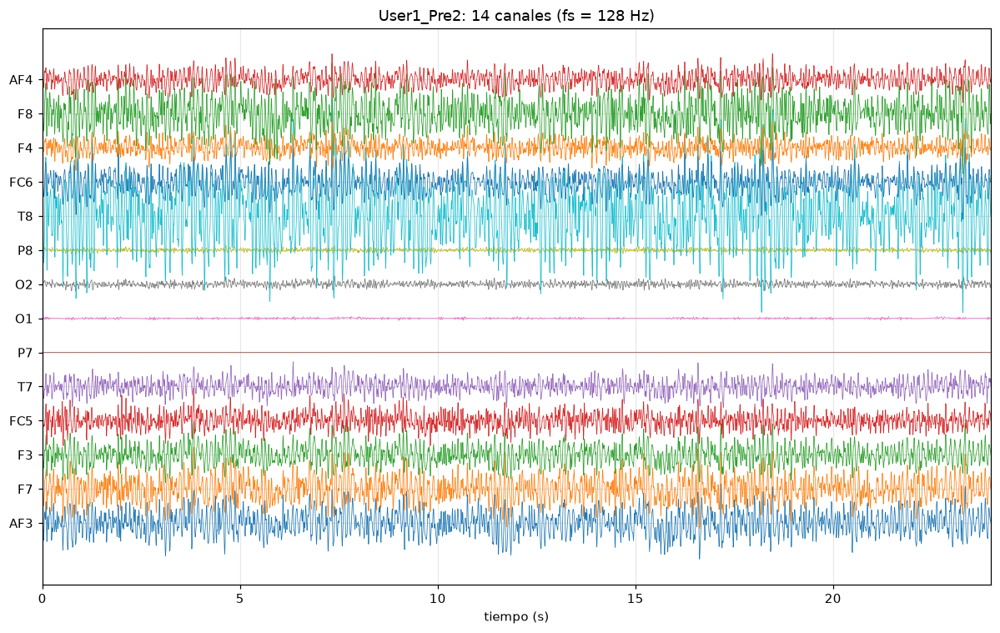

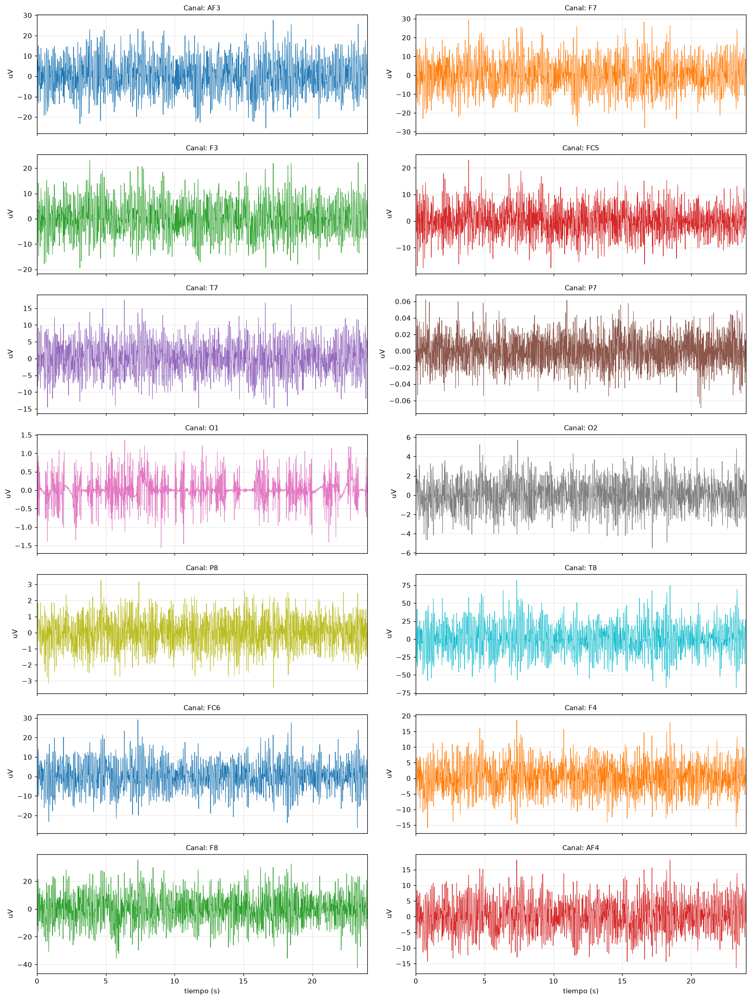

In [15]:
# vector de tiempo y estadisticas descriptivas
t = np.arange(len(datos)) / FS
resumen = datos.describe().T[["mean", "std", "min", "max"]]
resumen.columns = ["media", "desv_est", "minimo", "maximo"]
display(resumen.round(3))

# vista rápida
fig, ax = plt.subplots(figsize=(11, 7))
separacion = 4 * datos.std().mean()
for i, canal in enumerate(CANALES):
    ax.plot(t, datos[canal].values + i * separacion, lw=0.5)
ax.set_yticks([i * separacion for i in range(len(CANALES))])
ax.set_yticklabels(CANALES)
ax.set_xlabel("tiempo (s)")
ax.set_title("User1_Pre2: 14 canales (fs = 128 Hz)")
ax.set_xlim(0, t[-1])
plt.tight_layout()
plt.savefig(f"{CARPETA_SALIDA}/00.png", dpi=130)
plt.show()

# uno por uno
fig, axes = plt.subplots(7, 2, figsize=(15, 20), sharex=True)
axes = axes.flatten()

for i, canal in enumerate(CANALES):
    ax = axes[i]
    col = f"C{i % 10}"
    ax.plot(t, datos[canal].values, lw=0.6, color=col)
    ax.set_title(f"Canal: {canal}", fontsize=10)
    ax.set_ylabel("uV")
    ax.set_xlim(0, t[-1])

axes[-1].set_xlabel("tiempo (s)")
axes[-2].set_xlabel("tiempo (s)")

plt.tight_layout()
plt.savefig(f"{CARPETA_SALIDA}/01_canales_individuales.png", dpi=130)
plt.show()

## 3. Matriz de transición Taylor

Se utiliza la siguiente fórmula:

In [16]:
def matriz_transicion_taylor(dt, n_estados=N_ESTADOS, n_terminos=None, verbose=False):
    '''Matriz de transicion F = exp(A*dt) calculada con la SERIE DE TAYLOR.

    A es la matriz de "cadena de derivadas": A[i, i+1] = 1
    '''
    n = n_estados
    if n_terminos is None:
        n_terminos = n

    F = np.eye(n)
    for i in range(1, n_terminos):
        val = (dt ** i) / factorial(i)
        for row in range(n - i):
            F[row, row + i] = val
    return F

## 4. Definición de funciones para factorizar, actualizar y predecir estados en EnKF

### 1. Factorización LDL

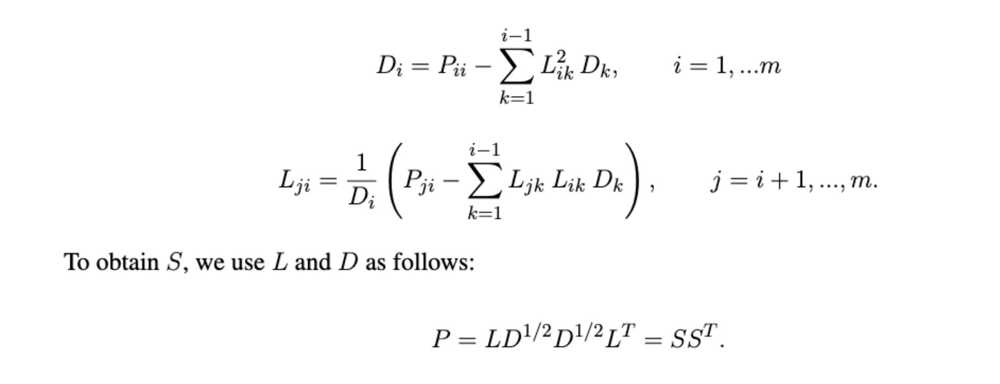

### 2. Predicción del estado Gram Schmidt

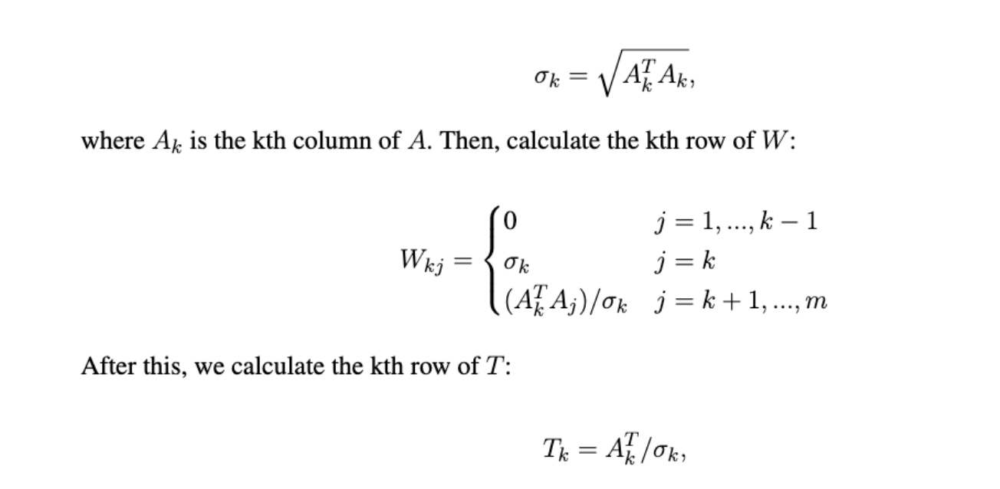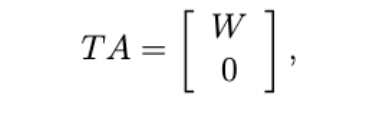

### 3. Actualización del estado Bierman

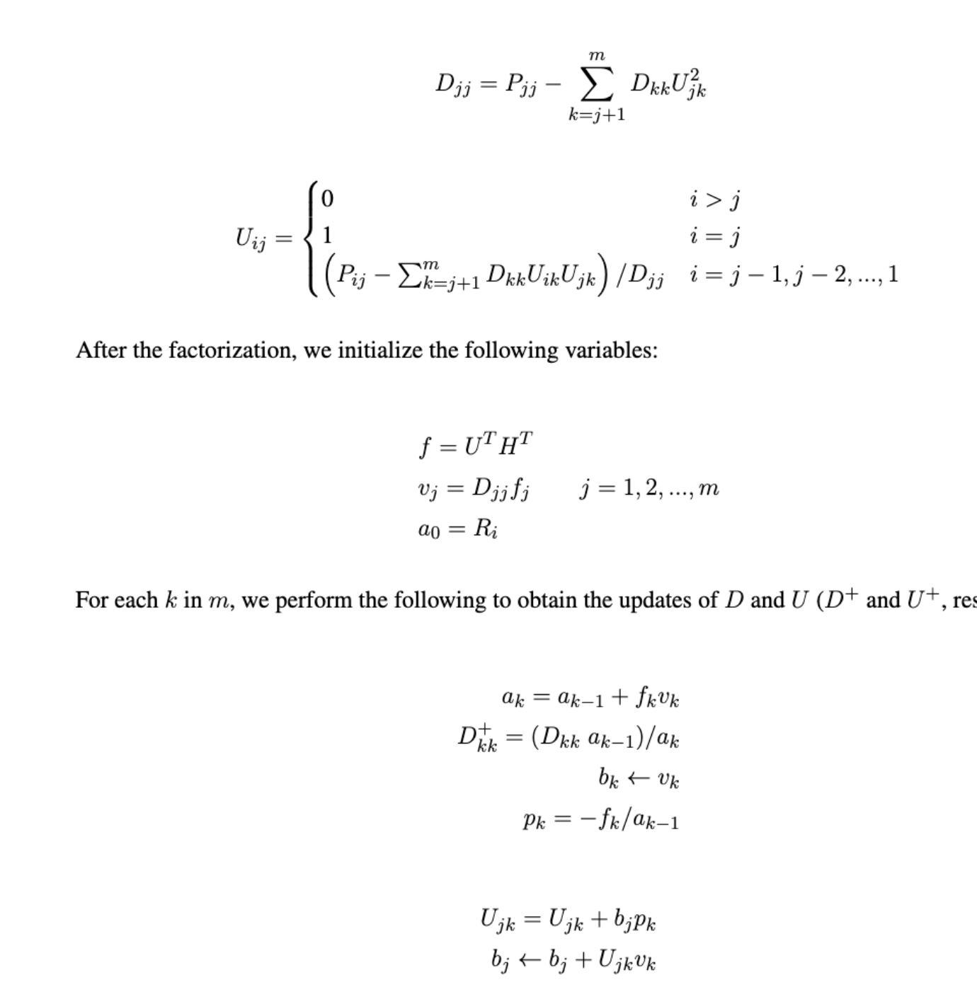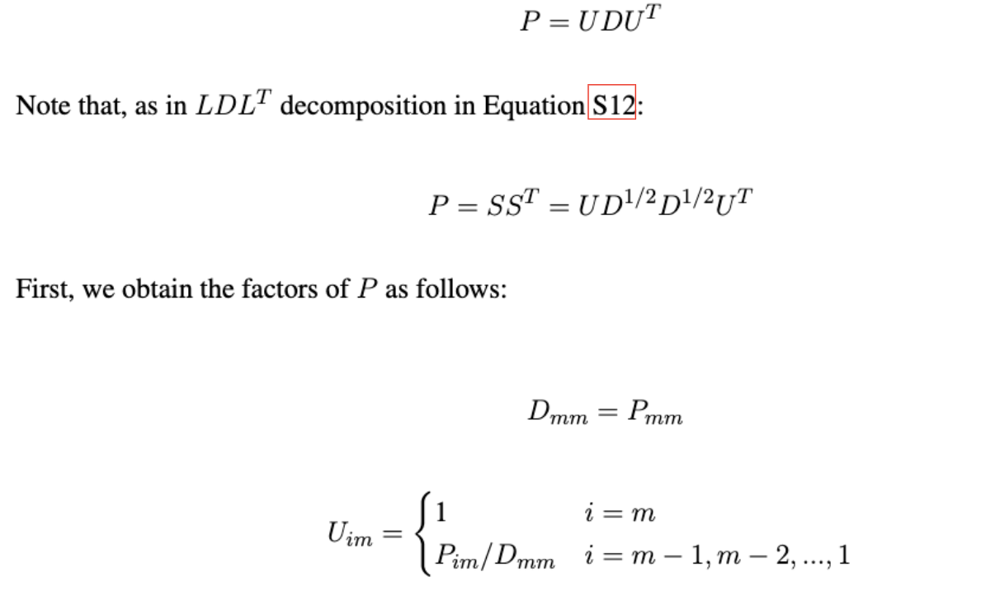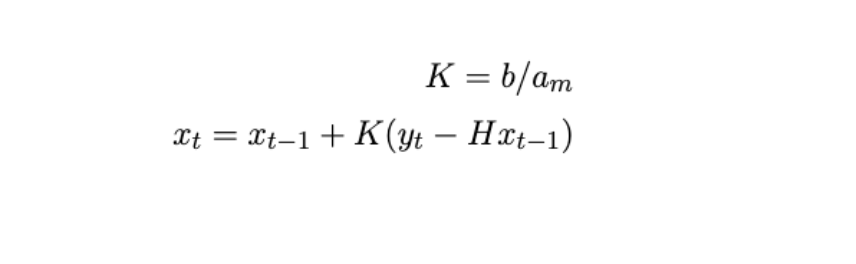

In [17]:
import numpy as np

def factorizacion_ldl(P):
    """Factorización P = L @ D @ L.T (S10 -> S12)"""
    m = P.shape[0]
    L = np.eye(m) # L debe ser matriz de identidad de m porque todas las sumas son de i o i+1 hasta m
    D = np.zeros(m) # mismo caso en D

    for i in range(m):
        suma_d = 0.0
        for k in range(i):
            suma_d += (L[i, k] ** 2) * D[k]
        D[i] = P[i, i] - suma_d

        for j in range(i + 1, m):
            suma_l = 0.0
            for k in range(i):
                suma_l += L[j, k] * L[i, k] * D[k]
            L[j, i] = (1.0 / D[i]) * (P[j, i] - suma_l)

    return L, np.diag(D) # diagonal por el uso de D**1/2 en la fórmula -> src: https://numpy.org/doc/stable/reference/generated/numpy.diag.html

def ensemble_from_covariance(x_mean, covariance, n_ensemble):
    """Construye un ensamble centrado con la media y covarianza indicadas."""
    x_mean = np.asarray(x_mean, dtype=float).reshape(-1)
    covariance = np.asarray(covariance, dtype=float)
    n_states = x_mean.size
    lower = np.linalg.cholesky(covariance)
    directions = np.zeros((n_states, n_ensemble))
    for i in range(n_states):
        denominator = np.sqrt((i + 1) * (i + 2))
        directions[i, :i + 1] = 1.0 / denominator
        directions[i, i + 1] = -(i + 1) / denominator
    deviations = lower @ directions * np.sqrt(n_ensemble - 1)
    return x_mean[:, None] + deviations


def predict_gram_schmidt(X_prev, F, Q_sqrt):
    """Predice un ensamble y su covarianza usando Gram-Schmidt modificado."""
    n_ensemble = X_prev.shape[1]
    n_states = X_prev.shape[0]
    X_forecast = F @ X_prev
    x_mean = np.mean(X_forecast, axis=1)
    anomalies = X_forecast - x_mean[:, None]
    A = np.hstack([anomalies / np.sqrt(n_ensemble - 1), Q_sqrt])

    orthogonal_rows = []
    R = np.zeros((n_states, n_states))
    for i in range(n_states):
        row = A[i].copy()
        for j, basis in enumerate(orthogonal_rows):
            R[j, i] = np.dot(basis, row)
            row -= R[j, i] * basis
        R[i, i] = np.linalg.norm(row)
        orthogonal_rows.append(row / R[i, i])

    covariance_sqrt = R.T
    covariance = covariance_sqrt @ covariance_sqrt.T
    return ensemble_from_covariance(x_mean, covariance, n_ensemble)

def bierman_update(x_prior, P_prior, z, H, R):
    """Actualización secuencial de Bierman con factorización LDL (S30 -> S37)"""
    m = len(x_prior)

    # Obtener factores U y D de P_prior (Eq. S32 y S33), donde U en la ecuación de los recursos es L
    U = np.eye(m)
    D = np.zeros(m)

    D[m-1] = P_prior[m-1, m-1]
    for i in range(m-1):
        U[i, m-1] = P_prior[i, m-1] / D[m-1]

    for j in range(m-2, -1, -1):
        suma_d = 0.0
        for k in range(j+1, m):
            suma_d += D[k] * (U[j, k] ** 2)
        D[j] = P_prior[j, j] - suma_d

        for i in range(j):
            suma_u = 0.0
            for k in range(j+1, m):
                suma_u += D[k] * U[i, k] * U[j, k]
            U[i, j] = (P_prior[i, j] - suma_u) / D[j]

    # Inicializar variables para la actualización de Bierman (Eq. S34)
    f = U.T @ H.flatten()
    v = np.zeros(m)
    for j in range(m):
        v[j] = D[j] * f[j]

    a = np.zeros(m + 1)
    a[0] = R

    b = v.copy()

    # Iteraciones de actualización (Eq. S35 y S36)
    for k in range(m):
        a[k+1] = a[k] + f[k] * v[k]
        D_new_k = (D[k] * a[k]) / a[k+1]
        D[k] = D_new_k

        p_k = -f[k] / a[k]

        for j in range(k):
            U_jk_old = U[j, k]
            U[j, k] = U_jk_old + b[j] * p_k
            b[j] = b[j] + U_jk_old * v[k]

    # Ganancia de Kalman y Actualización del Estado (Eq. S37)
    K = b / a[m]
    res = z - H @ x_prior
    x_updated = x_prior + K * res

    P_updated = U @ np.diag(D) @ U.T
    return x_updated, P_updated

## 5. Aplicacion del EnKF y analisis espectral

El EnKF se aplica directamente a todos los canales EEG. La predicción emplea Gram-Schmidt y la actualización secuencial de Bierman con LDL. Para cada canal se grafican la señal original, la estimación del EnKF y sus densidades espectrales de potencia, usando la frecuencia real de muestreo (128 Hz).

Procesando AF3...
Error relativo Bierman vs Kalman: estado=1.95e-14, covarianza=6.33e-16


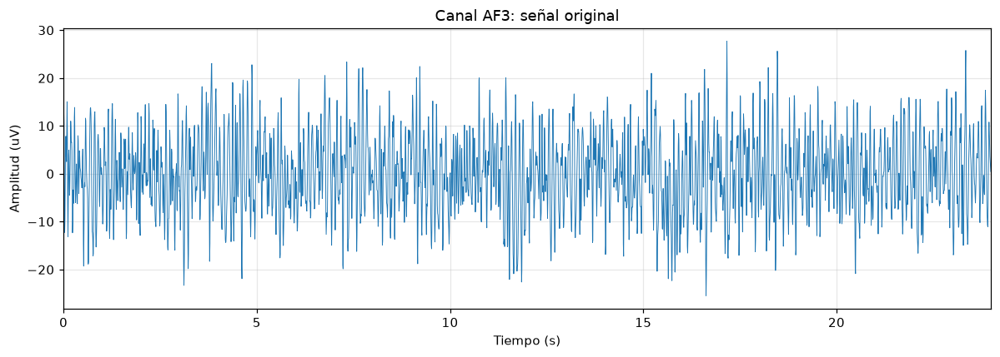

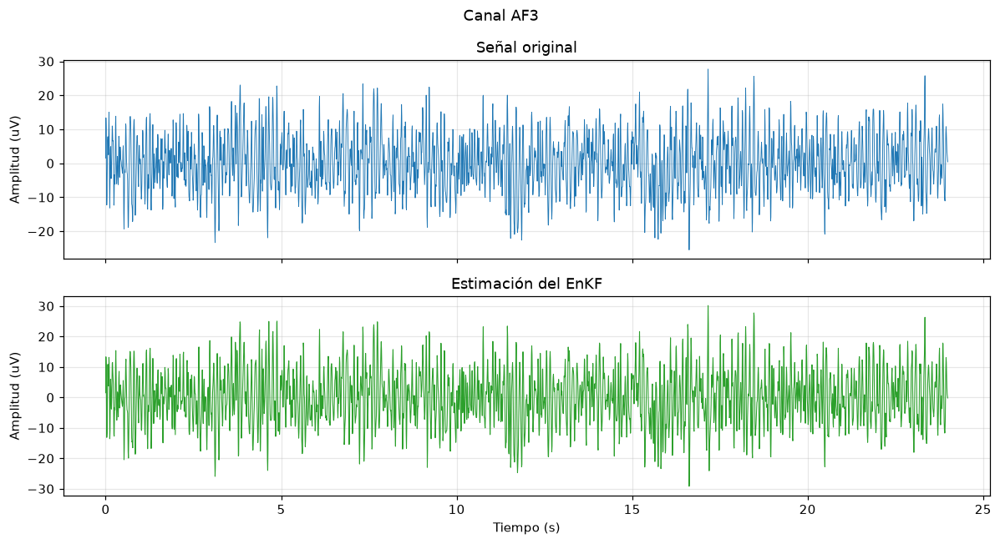

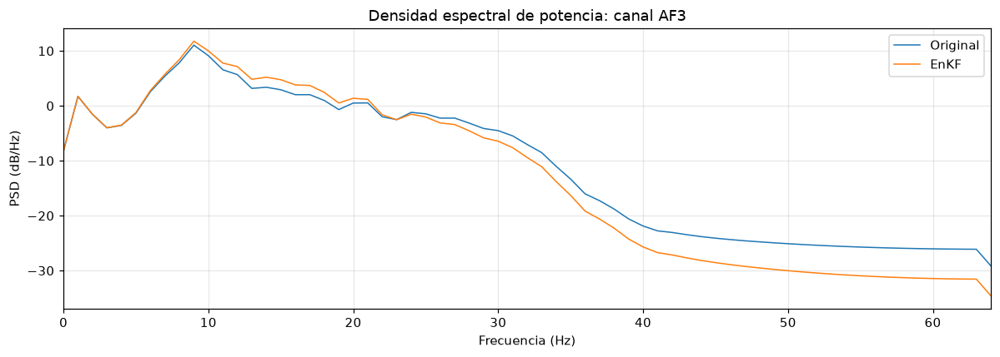

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando F7...
Error relativo Bierman vs Kalman: estado=2.69e-14, covarianza=4.97e-16


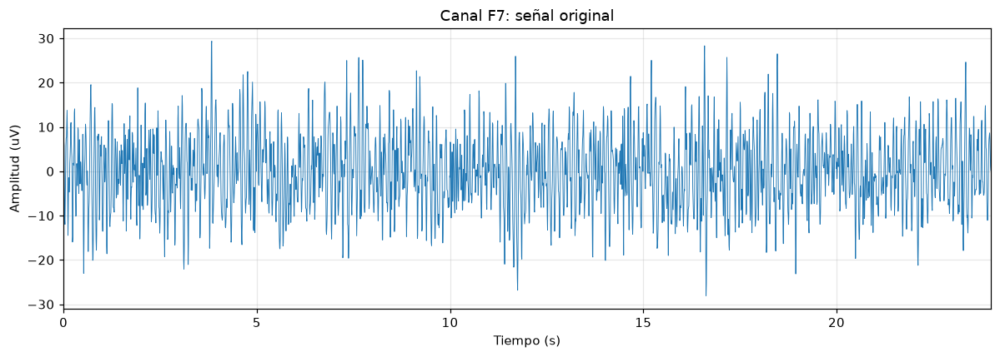

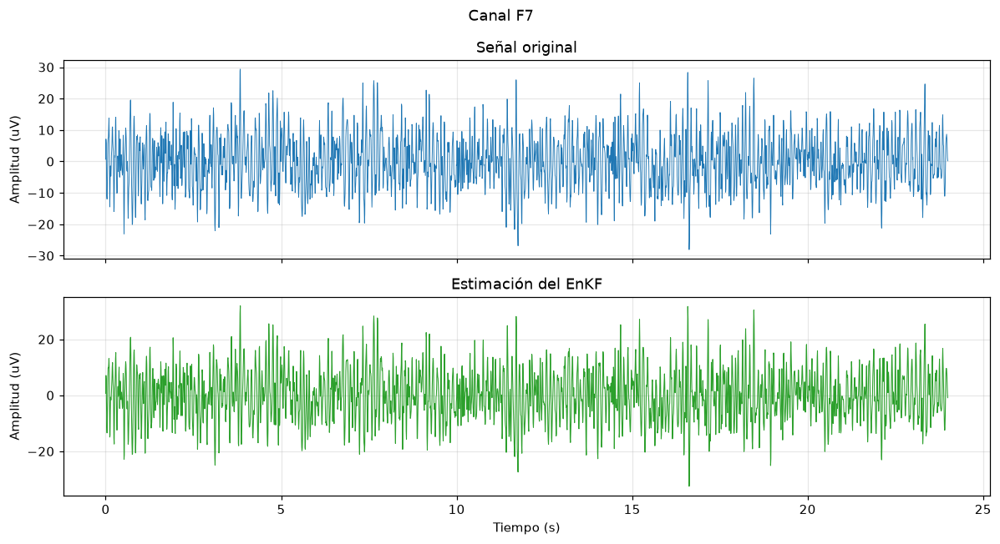

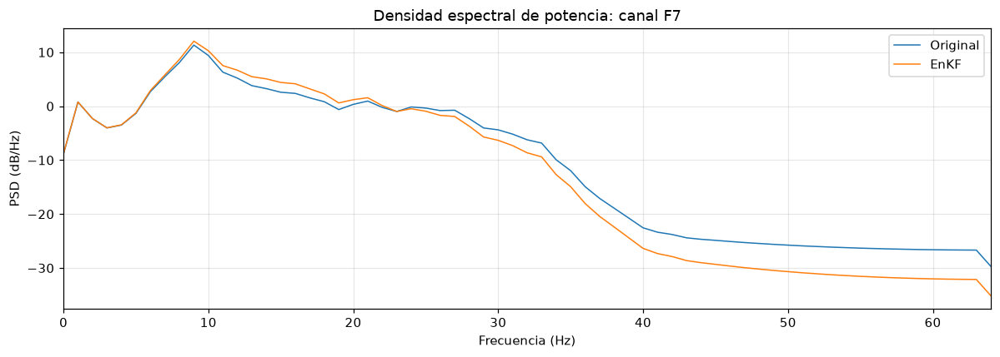

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando F3...
Error relativo Bierman vs Kalman: estado=3.98e-14, covarianza=6.48e-16


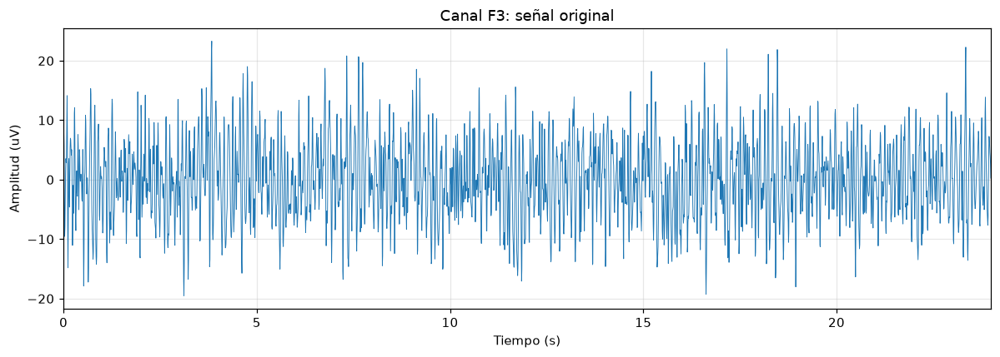

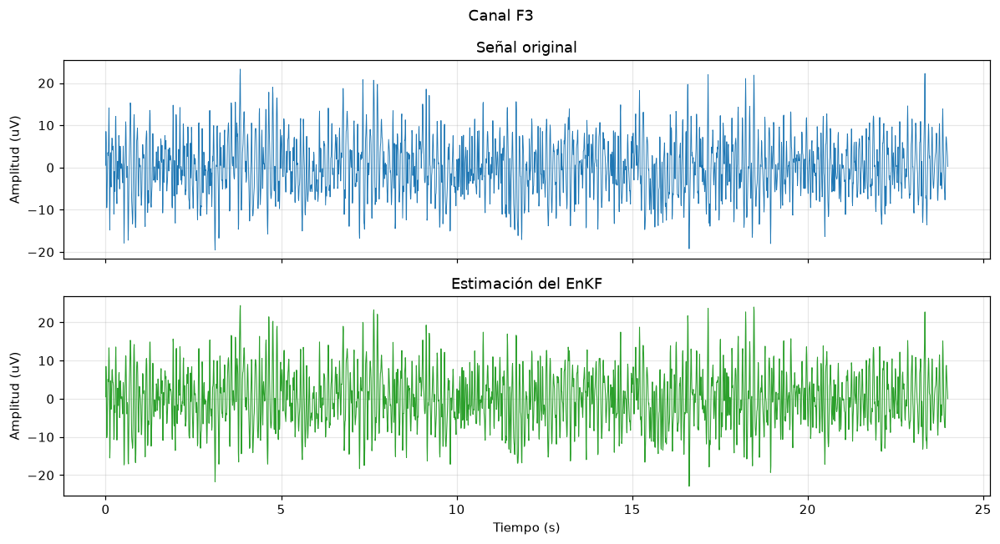

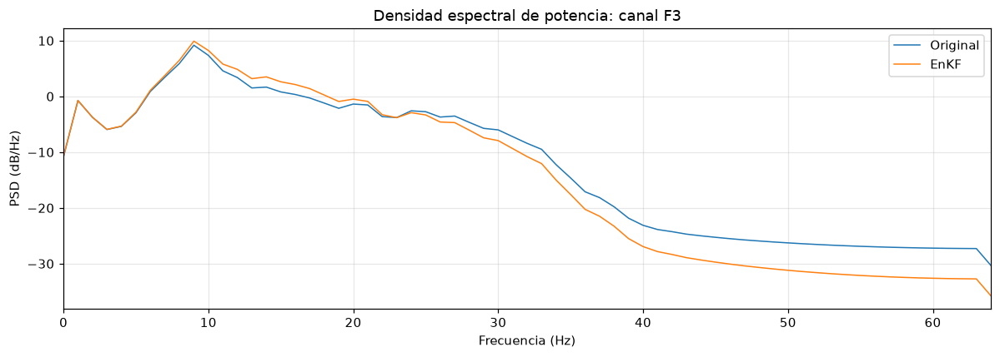

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando FC5...
Error relativo Bierman vs Kalman: estado=3.25e-14, covarianza=7.60e-16


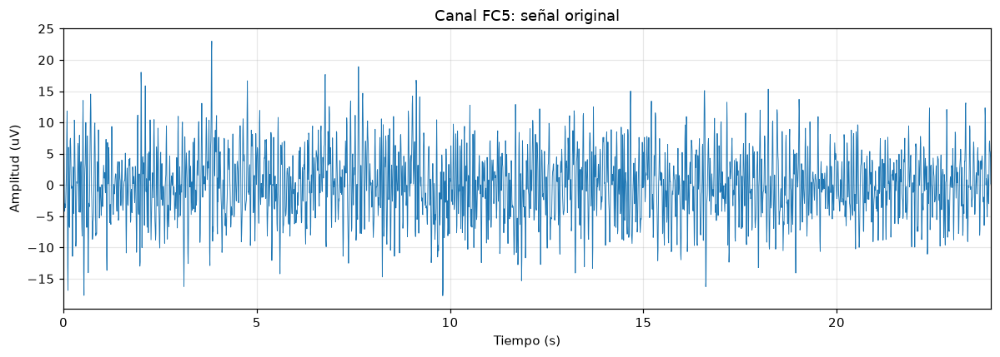

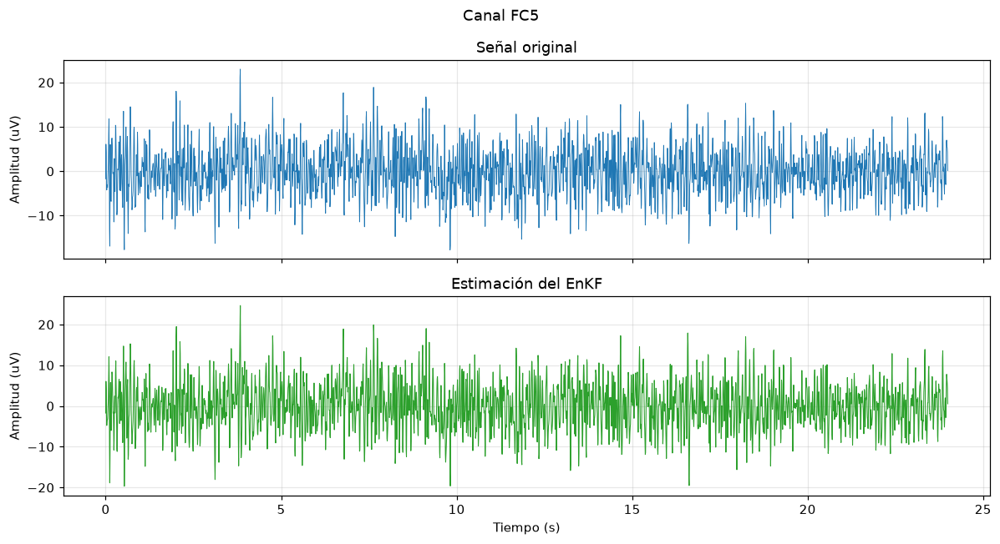

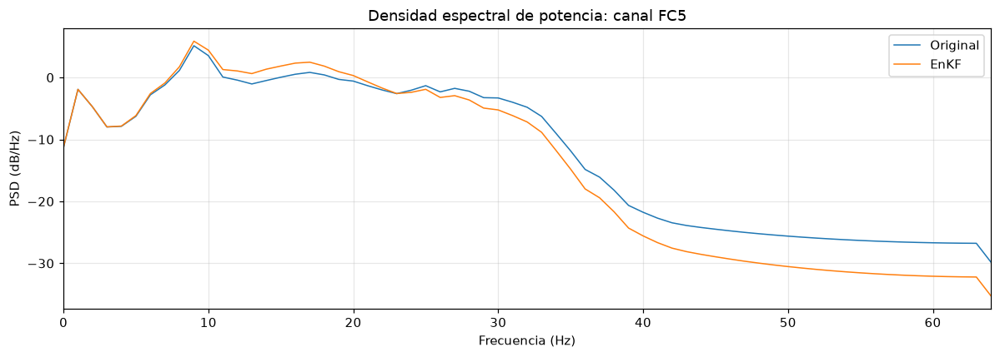

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando T7...
Error relativo Bierman vs Kalman: estado=1.86e-14, covarianza=5.61e-16


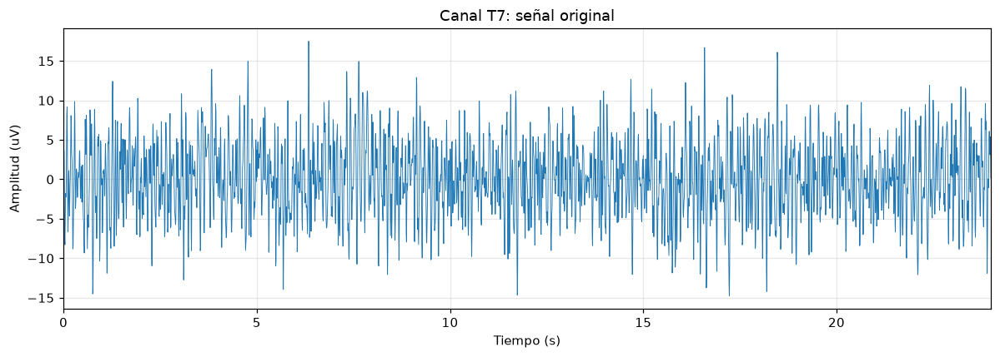

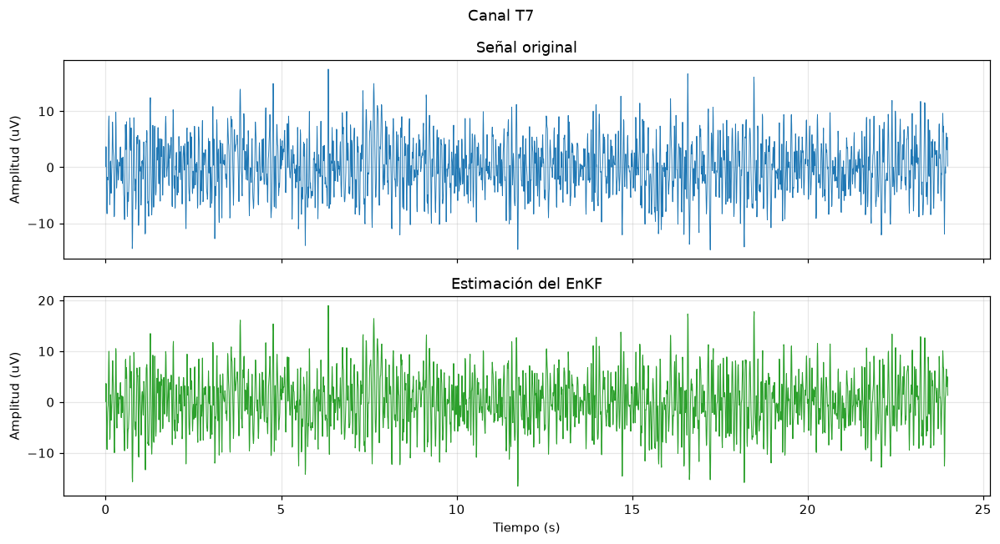

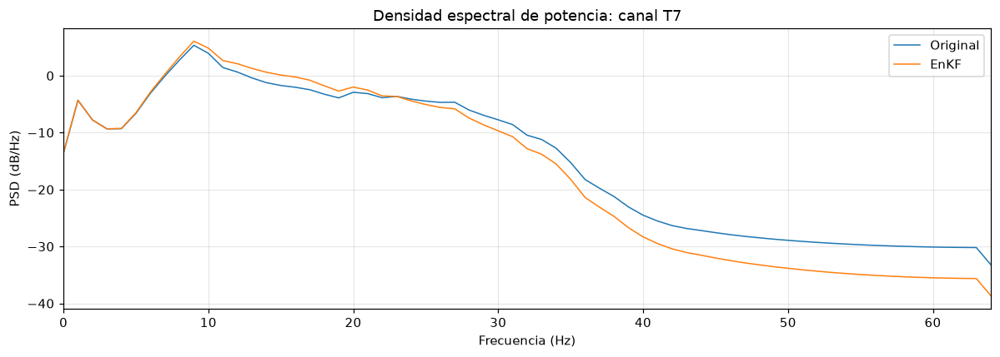

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando P7...
Error relativo Bierman vs Kalman: estado=1.68e-14, covarianza=2.01e-15


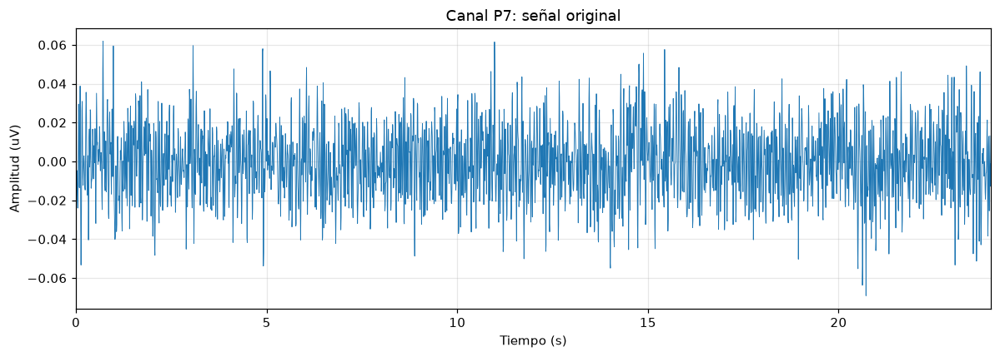

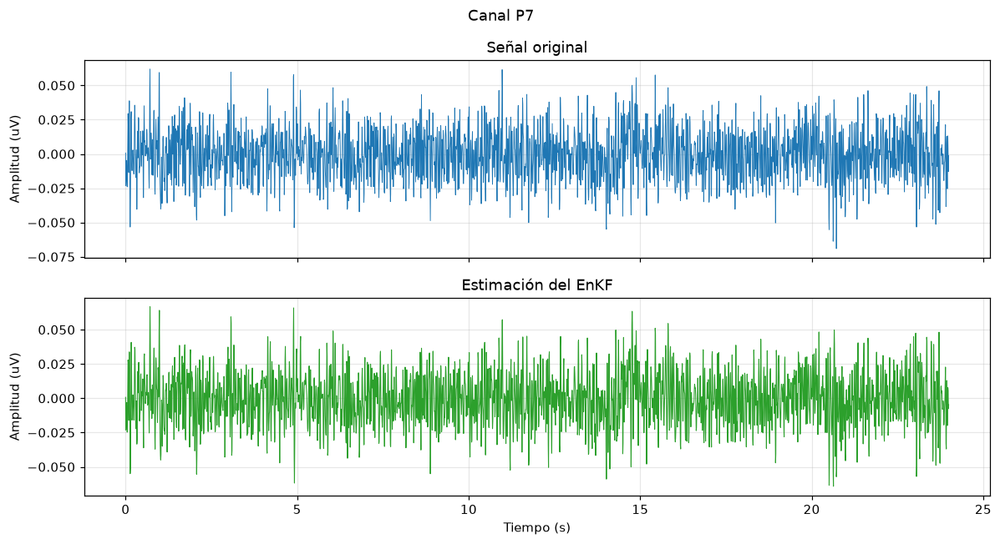

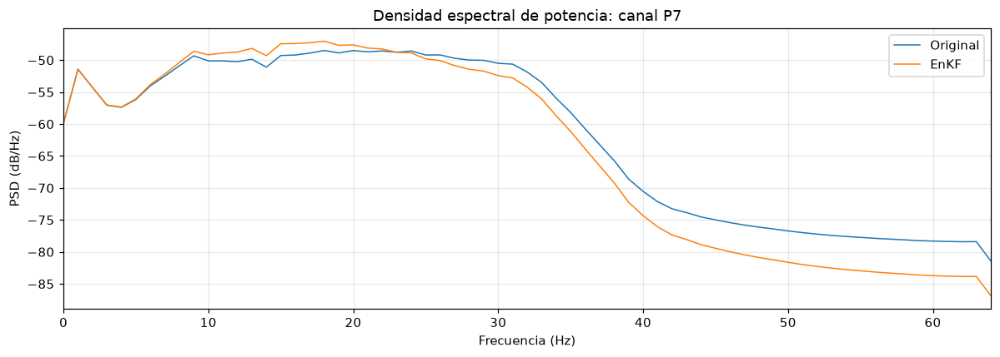

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando O1...
Error relativo Bierman vs Kalman: estado=3.13e-14, covarianza=1.16e-15


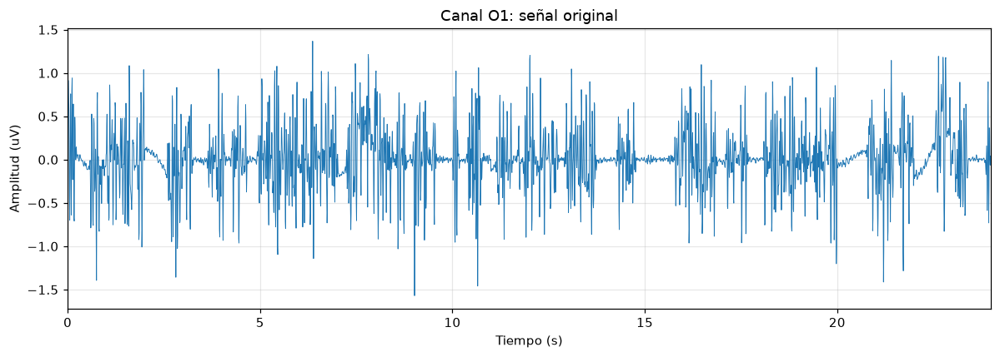

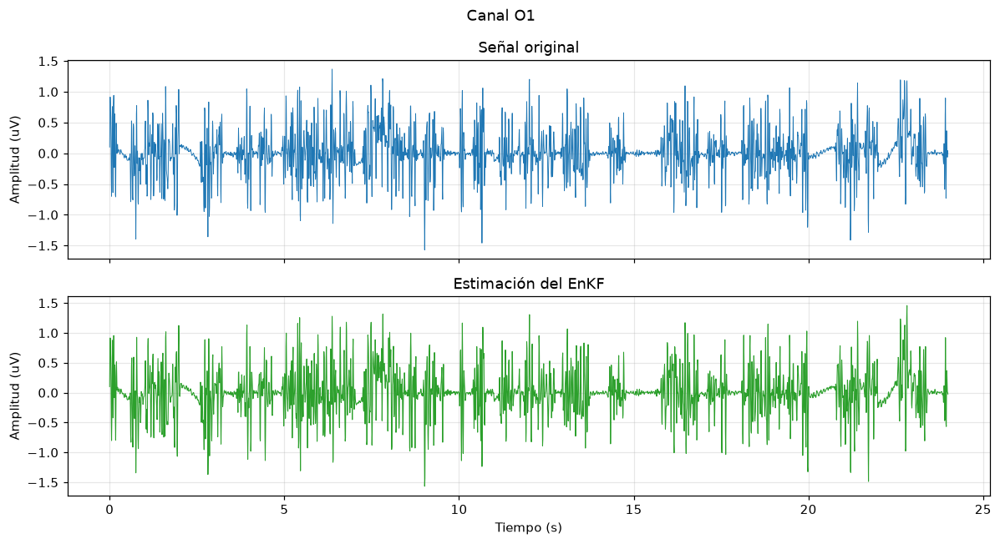

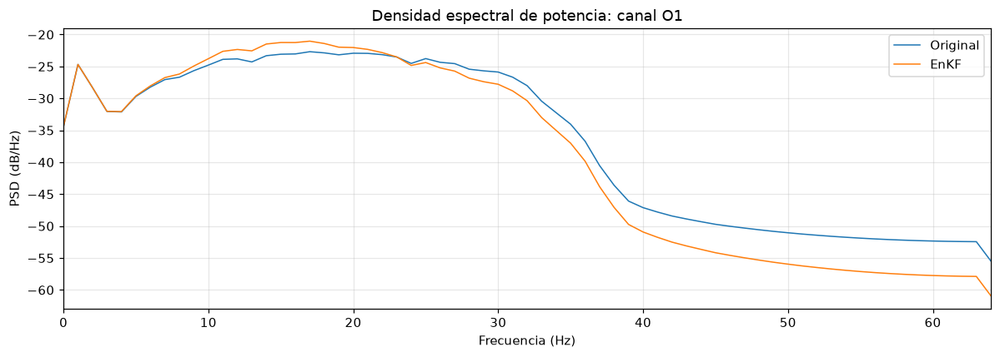

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando O2...
Error relativo Bierman vs Kalman: estado=3.62e-14, covarianza=2.13e-15


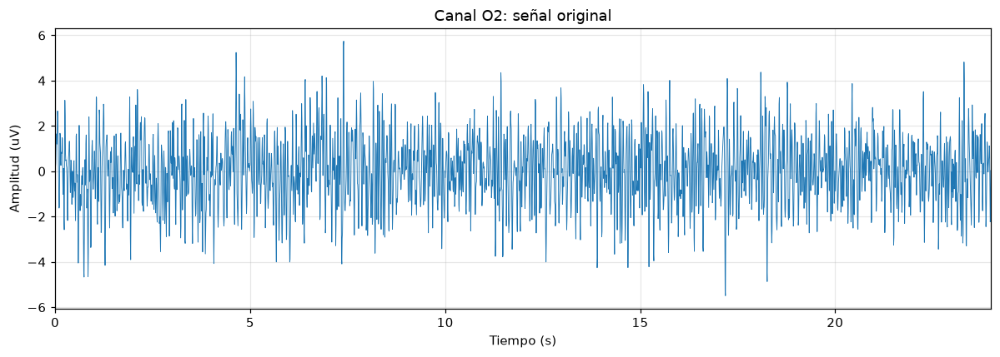

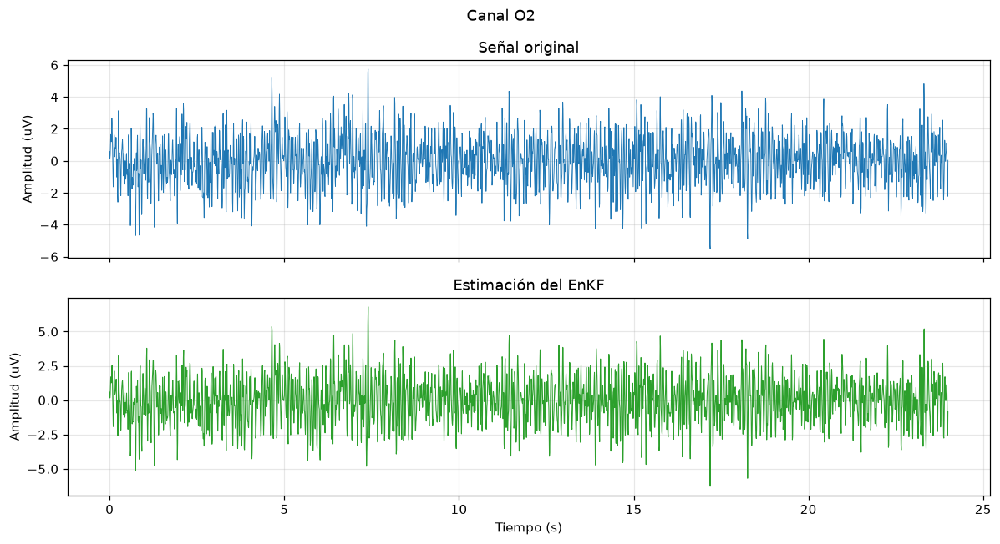

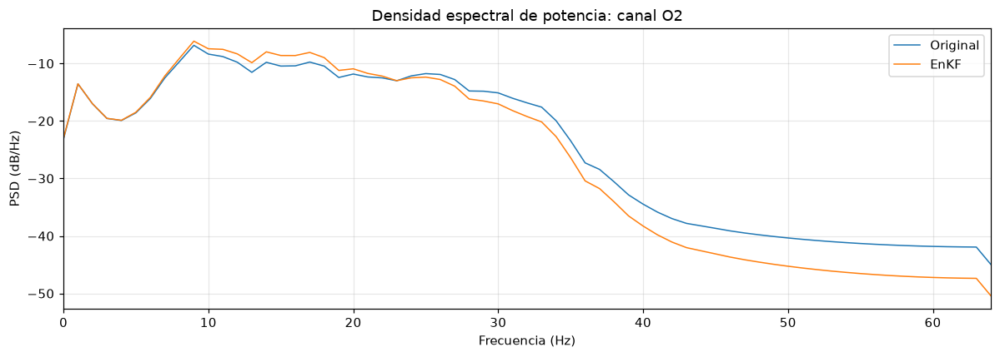

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando P8...
Error relativo Bierman vs Kalman: estado=4.42e-14, covarianza=6.39e-16


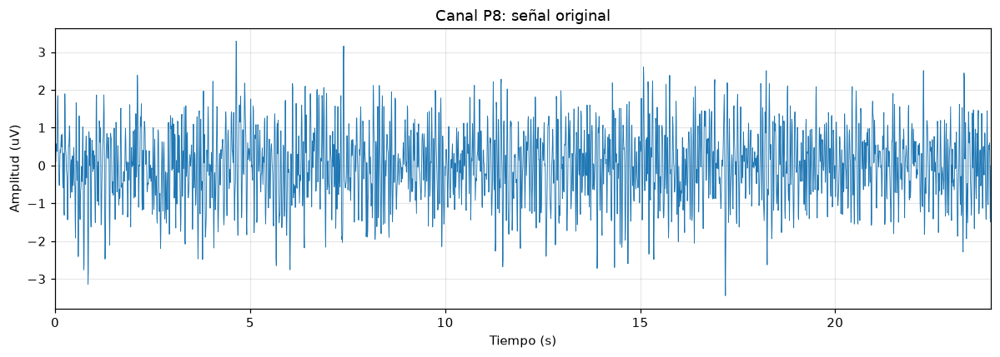

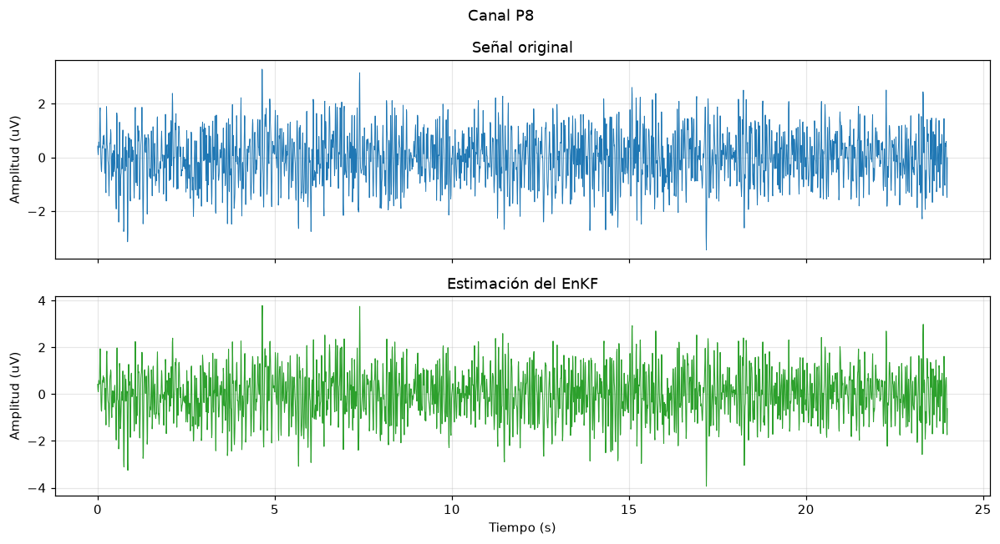

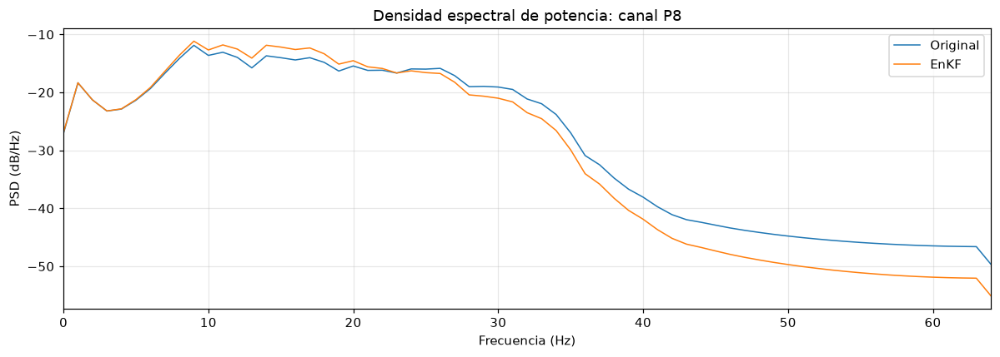

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando T8...
Error relativo Bierman vs Kalman: estado=2.34e-14, covarianza=6.18e-16


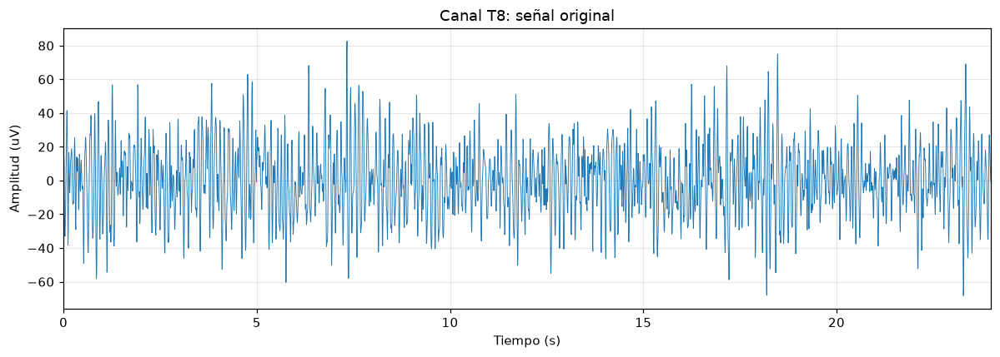

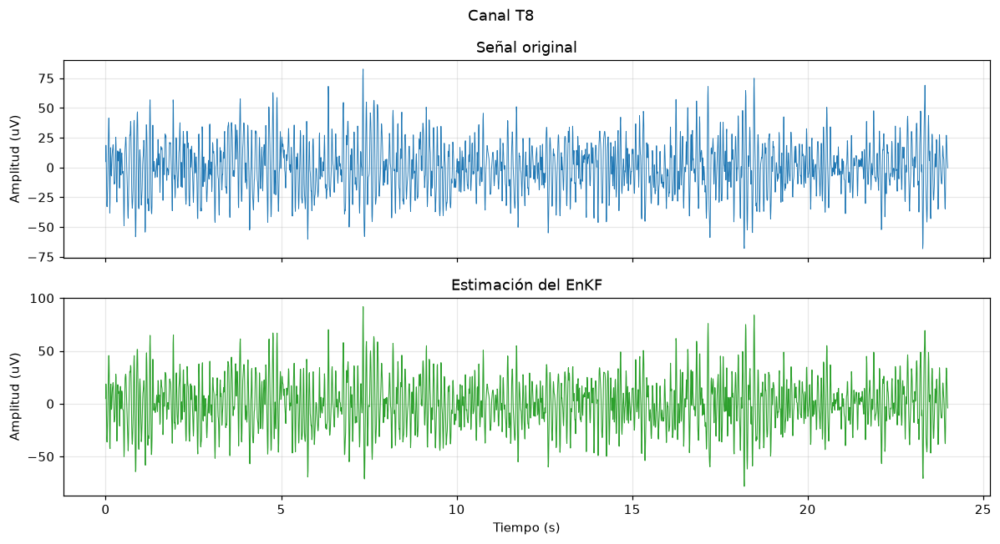

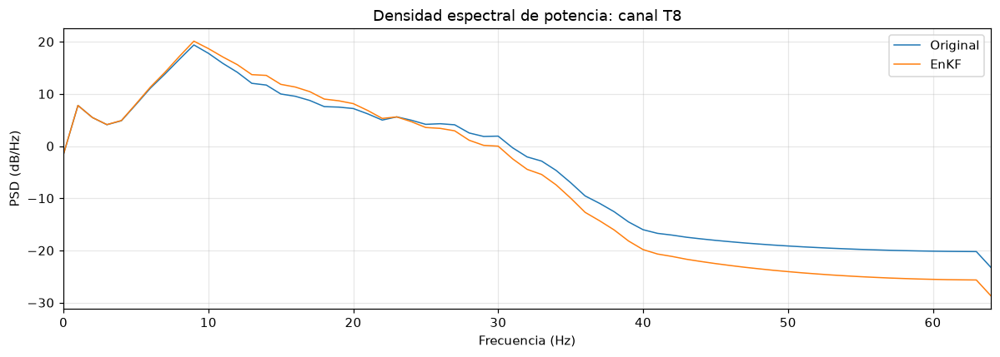

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando FC6...
Error relativo Bierman vs Kalman: estado=2.64e-14, covarianza=3.73e-16


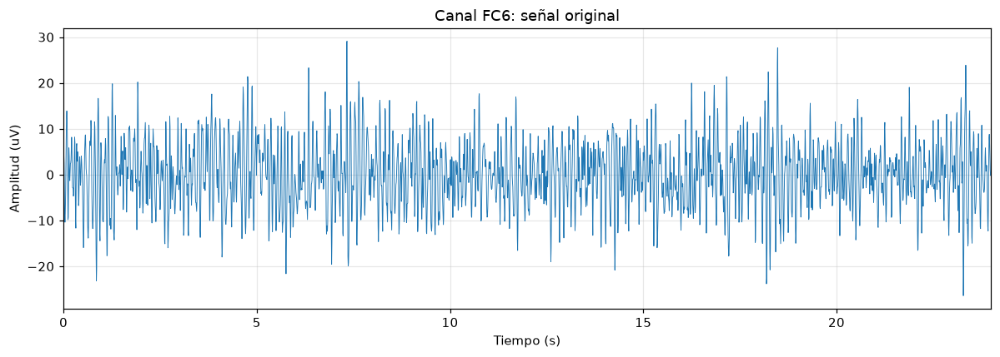

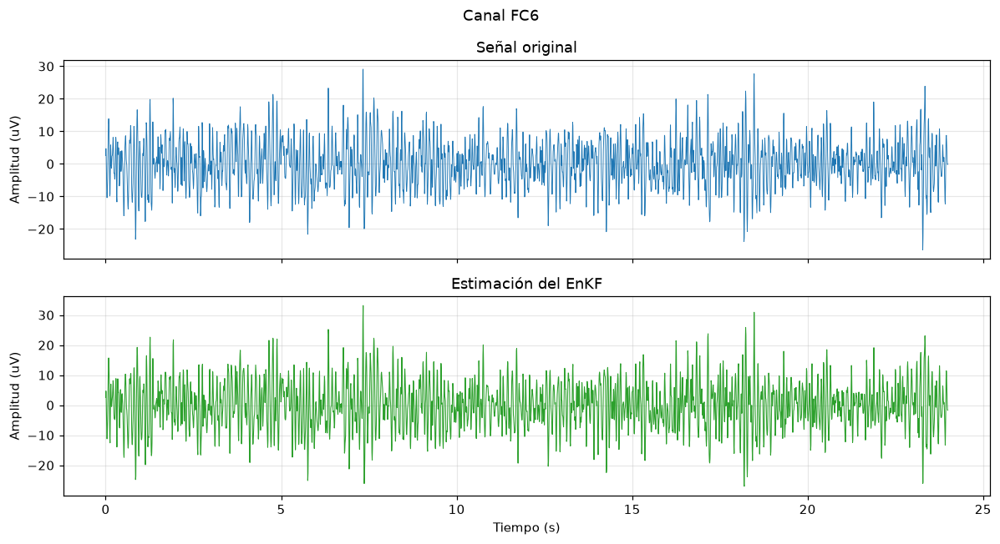

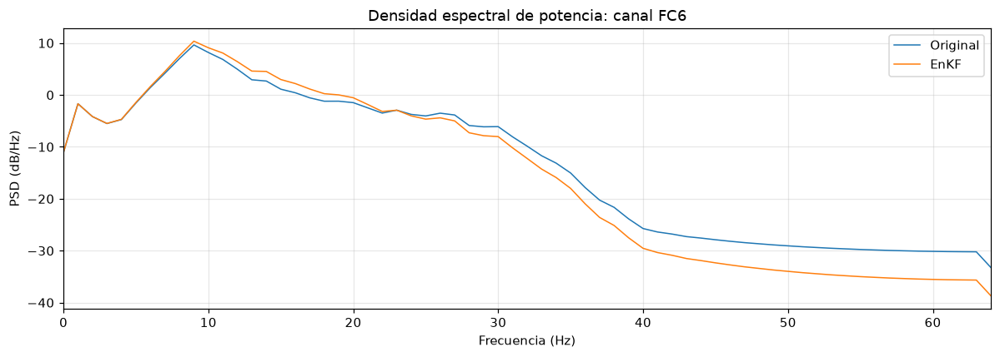

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando F4...
Error relativo Bierman vs Kalman: estado=2.71e-14, covarianza=1.15e-15


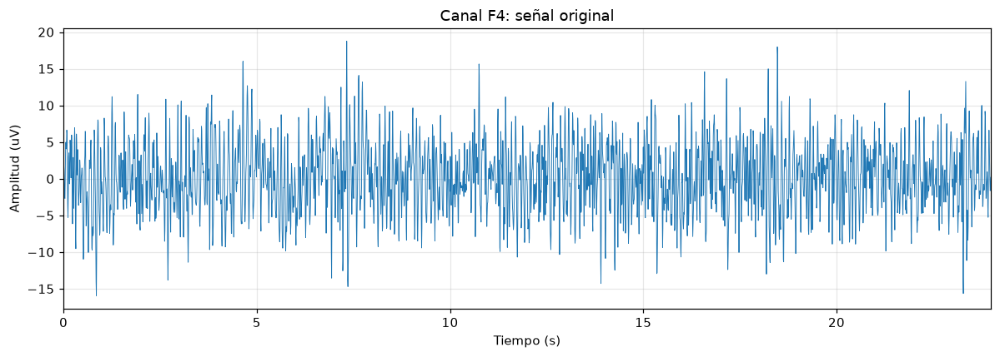

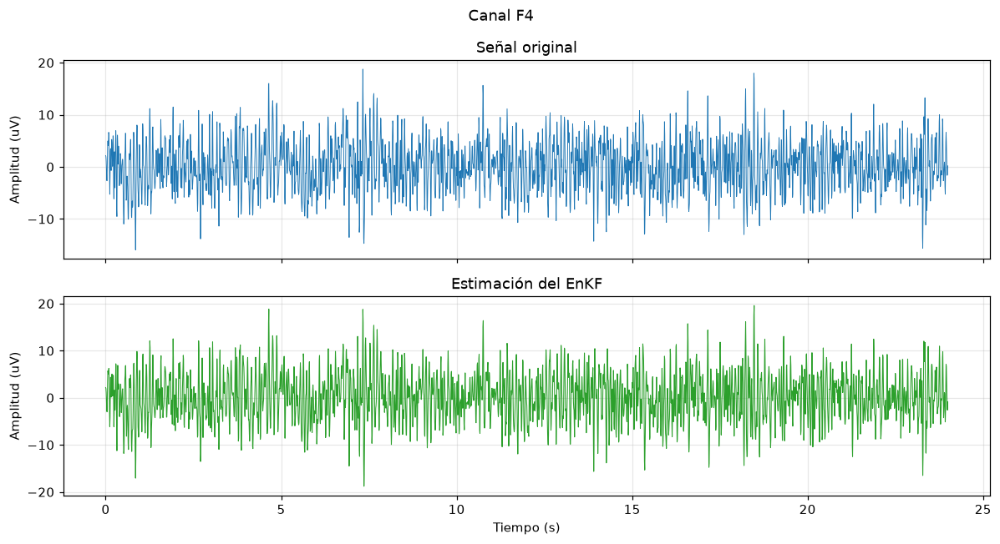

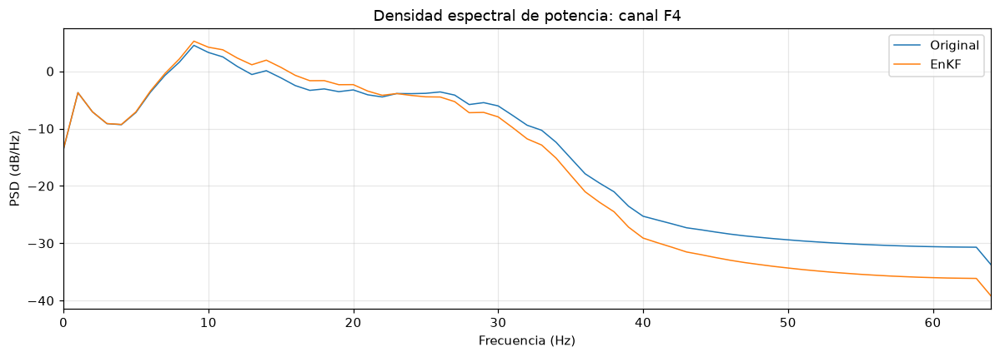

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando F8...
Error relativo Bierman vs Kalman: estado=1.51e-13, covarianza=3.50e-16


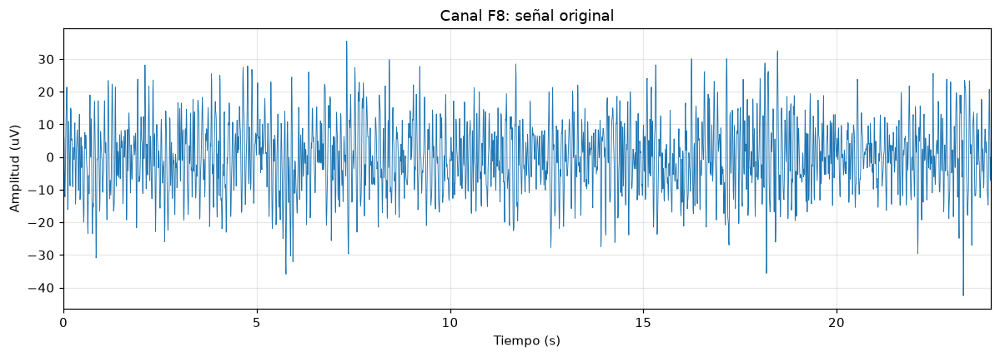

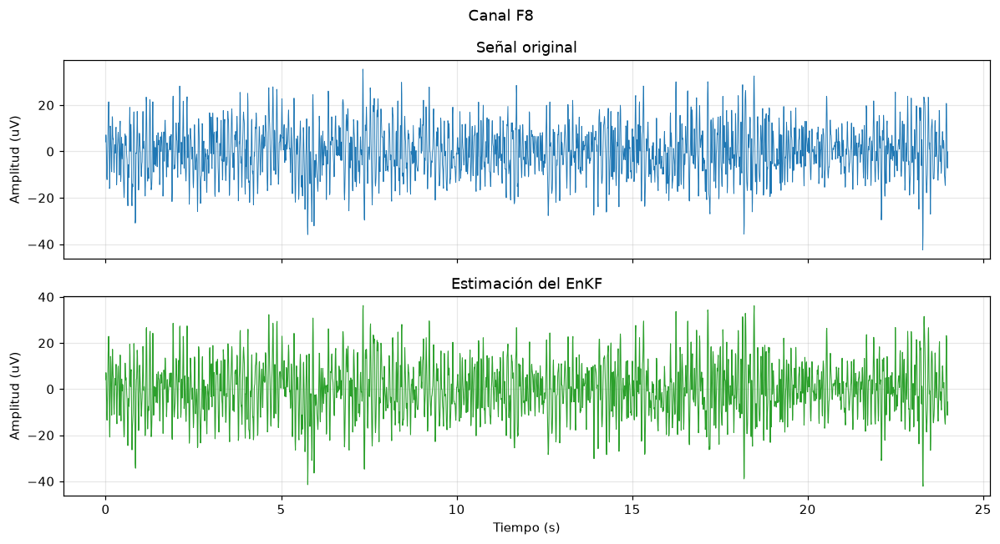

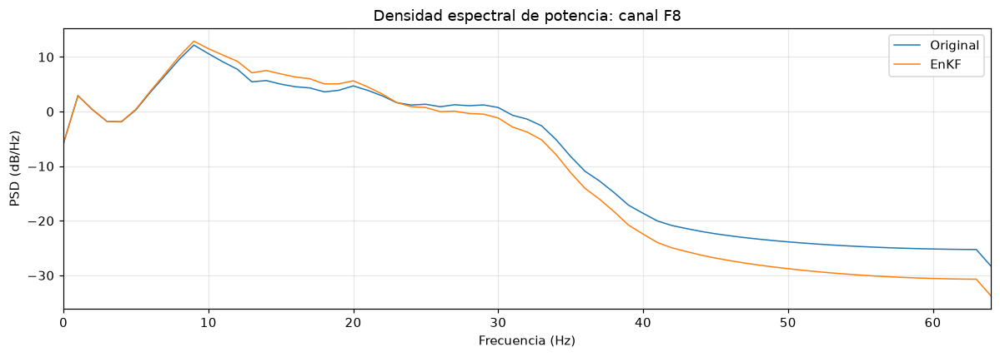

  EnKF: 3072 muestras, 30 miembros; finita: True
Procesando AF4...
Error relativo Bierman vs Kalman: estado=2.74e-14, covarianza=8.28e-16


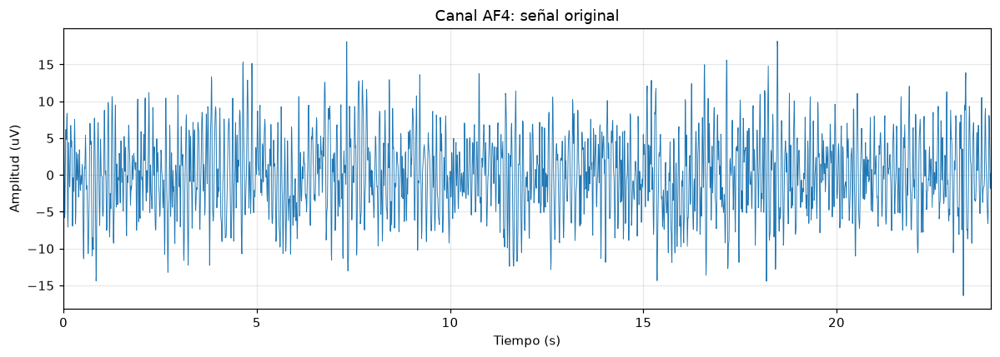

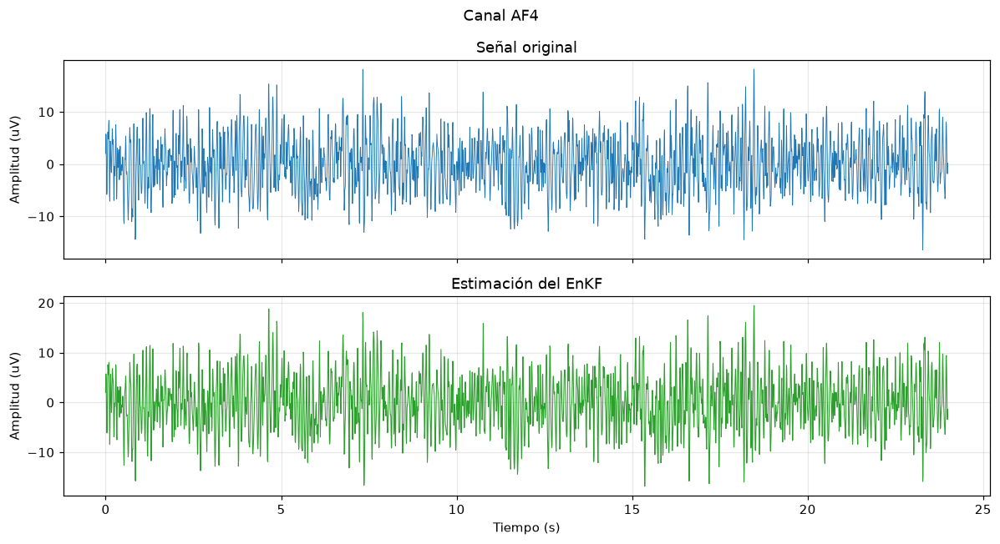

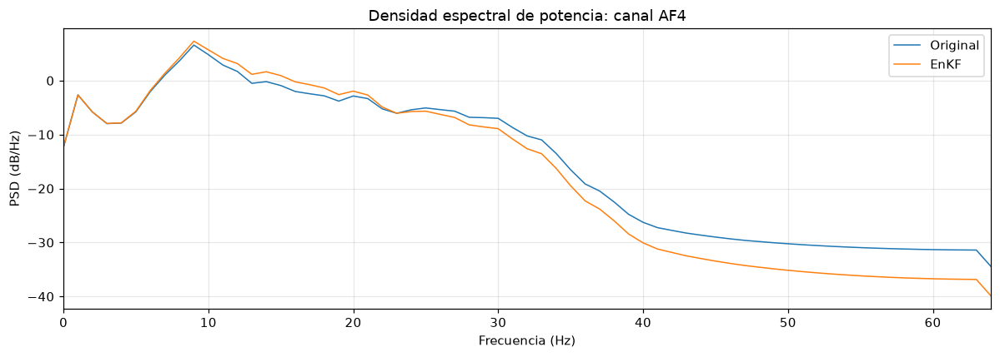

  EnKF: 3072 muestras, 30 miembros; finita: True
Canales procesados: 14 de 14
Tres graficas por canal guardadas en 'resultados_enkf'.


In [18]:
from scipy import signal

N_ENSEMBLE = 30


def obtener_psd(senal, frecuencia_muestreo=FS):
    """Calcula la densidad espectral de potencia de Welch en dB/Hz."""
    senal = np.asarray(senal, dtype=float)
    frecuencia, potencia = signal.welch(
        senal,
        fs=frecuencia_muestreo,
        nperseg=min(int(frecuencia_muestreo), senal.size),
    )
    potencia_db = 10 * np.log10(np.maximum(potencia, np.finfo(float).tiny))
    return frecuencia, potencia_db


def graficar_senal(tiempo, senal, canal):
    fig, ax = plt.subplots()
    ax.plot(tiempo, senal, lw=0.6)
    ax.set_title(f"Canal {canal}: señal original")
    ax.set_xlabel("Tiempo (s)")
    ax.set_ylabel("Amplitud (uV)")
    ax.set_xlim(0, tiempo[-1])
    fig.tight_layout()
    fig.savefig(os.path.join(CARPETA_SALIDA, f"02_senal_{canal}.png"), dpi=130)
    plt.show()
    plt.close(fig)


def graficar_comparacion(tiempo, original, estimacion_enkf, canal):
    fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(11, 6))
    ax1.plot(tiempo, original, lw=0.6)
    ax1.set_title("Señal original")
    ax1.set_ylabel("Amplitud (uV)")
    ax2.plot(tiempo, estimacion_enkf, lw=0.7, color="C2")
    ax2.set_title("Estimación del EnKF")
    ax2.set_xlabel("Tiempo (s)")
    ax2.set_ylabel("Amplitud (uV)")
    fig.suptitle(f"Canal {canal}")
    fig.tight_layout()
    fig.savefig(os.path.join(CARPETA_SALIDA, f"03_enkf_{canal}.png"), dpi=130)
    plt.show()
    plt.close(fig)


def graficar_psd(frecuencia, psd_original, psd_enkf, canal, frecuencia_muestreo=FS):
    fig, ax = plt.subplots()
    ax.plot(frecuencia, psd_original, label="Original", lw=1)
    ax.plot(frecuencia, psd_enkf, label="EnKF", lw=1)
    ax.set_xlim(0, frecuencia_muestreo / 2)
    ax.set_title(f"Densidad espectral de potencia: canal {canal}")
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("PSD (dB/Hz)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(CARPETA_SALIDA, f"04_psd_{canal}.png"), dpi=130)
    plt.show()
    plt.close(fig)


def aplicar_enkf(observaciones, frecuencia_muestreo=FS, n_ensemble=N_ENSEMBLE,
                 fraccion_ruido_medicion=0.1, fraccion_ruido_proceso=0.02):
    """Filtra observaciones escalares con predicción Gram-Schmidt y actualización Bierman."""
    observaciones = np.asarray(observaciones, dtype=float)
    n_states = N_ESTADOS
    dt = 1.0 / frecuencia_muestreo
    variance = max(float(np.var(observaciones)), 1e-12)
    R = fraccion_ruido_medicion * variance
    process_intensity = fraccion_ruido_proceso * variance / dt**4
    process_direction = np.array([dt**2 / 2, dt, 1.0])[:, None]
    Q_sqrt = np.sqrt(process_intensity) * process_direction
    F = matriz_transicion_taylor(dt, n_states)
    H = np.array([[1.0, 0.0, 0.0]])

    initial_mean = np.array([observaciones[0], 0.0, 0.0])
    initial_variance = 10.0 * variance
    initial_covariance = np.diag([
        initial_variance,
        initial_variance / dt**2,
        initial_variance / dt**4,
    ])
    ensemble = ensemble_from_covariance(initial_mean, initial_covariance, n_ensemble)
    estimate = np.empty(observaciones.size)
    estimate[0] = initial_mean[0]

    error_estado = 0.0
    error_covarianza = 0.0
    for i in range(1, observaciones.size):
        ensemble_prior = predict_gram_schmidt(ensemble, F, Q_sqrt)
        x_prior = np.mean(ensemble_prior, axis=1)
        anomalies = ensemble_prior - x_prior[:, None]
        P_prior = anomalies @ anomalies.T / (n_ensemble - 1)
        x_updated, P_updated = bierman_update(x_prior, P_prior, observaciones[i], H, R)
        P_updated = (P_updated + P_updated.T) / 2
        ganancia = P_prior @ H.T / (H @ P_prior @ H.T + R)[0, 0]
        x_referencia = x_prior + ganancia[:, 0] * (observaciones[i] - (H @ x_prior)[0])
        P_referencia = P_prior - ganancia @ H @ P_prior
        error_estado = max(error_estado, np.max(np.abs(x_updated - x_referencia)) / max(1, np.max(np.abs(x_referencia))))
        error_covarianza = max(error_covarianza, np.max(np.abs(P_updated - P_referencia)) / max(1, np.max(np.abs(P_referencia))))
        estimate[i] = x_updated[0]
        ensemble = ensemble_from_covariance(x_updated, P_updated, n_ensemble)

    print(f"Error relativo Bierman vs Kalman: estado={error_estado:.2e}, covarianza={error_covarianza:.2e}")
    return estimate


def analizar_canal(datos, canal, frecuencia_muestreo=FS):
    original = datos[canal].to_numpy(dtype=float)
    tiempo = np.arange(original.size) / frecuencia_muestreo
    estimacion_enkf = aplicar_enkf(original, frecuencia_muestreo)
    frecuencia, psd_original = obtener_psd(original, frecuencia_muestreo)
    _, psd_enkf = obtener_psd(estimacion_enkf, frecuencia_muestreo)

    graficar_senal(tiempo, original, canal)
    graficar_comparacion(tiempo, original, estimacion_enkf, canal)
    graficar_psd(frecuencia, psd_original, psd_enkf, canal, frecuencia_muestreo)
    return {
        "tiempo": tiempo,
        "original": original,
        "estimacion_enkf": estimacion_enkf,
        "frecuencia": frecuencia,
        "psd_original_db": psd_original,
        "psd_enkf_db": psd_enkf,
    }


resultados_analisis = {}
for canal in CANALES:
    print(f"Procesando {canal}...")
    resultados_analisis[canal] = analizar_canal(datos, canal)
    estimacion = resultados_analisis[canal]["estimacion_enkf"]
    print(f"  EnKF: {len(estimacion)} muestras, {N_ENSEMBLE} miembros; finita: {np.all(np.isfinite(estimacion))}")

print(f"Canales procesados: {len(resultados_analisis)} de {len(CANALES)}")
print(f"Tres graficas por canal guardadas en '{CARPETA_SALIDA}'.")